# CommerceIQ — Phase 11: Advanced Customer Intelligence (`customer_unique_id`)

**Reference Analysis Date:** `2018-09-01` (immediately following the Core Period end `2018-08-31`; never uses real-world current dates against 2016–2018 history).  
**Identity Rule:** All customer metrics aggregate by persistent `customer_unique_id`, never order-specific `customer_id`.  
**Financial Rule:** Observed customer value reflects historical delivered merchandise BRL, not platform profit or verified lifetime margin.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
PROJECT_ROOT = Path.cwd()
PARQUET_DIR = PROJECT_ROOT / "data" / "processed" / "parquet"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

orders = pd.read_parquet(PARQUET_DIR / "orders.parquet")
orders["purchase_date"] = pd.to_datetime(orders["purchase_date"])
customers = pd.read_parquet(PARQUET_DIR / "customers.parquet")
order_items = pd.read_parquet(PARQUET_DIR / "order_items.parquet")
order_items["price"] = order_items["price"].astype(float)

item_agg = order_items.groupby("order_id", as_index=False).agg(merch_brl=("price", "sum"))
deliv = (
    orders[orders["order_status"].eq("delivered") & orders["has_order_items"]]
    .merge(customers[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="inner")
    .merge(item_agg, on="order_id", how="inner")
)
REF_DATE = pd.Timestamp("2018-09-01")
MAX_OBS_DATE = deliv["purchase_date"].max()

rfm = deliv.groupby("customer_unique_id", as_index=False).agg(
    last_purchase=("purchase_date", "max"),
    first_purchase=("purchase_date", "min"),
    frequency=("order_id", "count"),
    monetary_brl=("merch_brl", "sum"),
    primary_state=("customer_state", "first"),
)
rfm["recency_days"] = (REF_DATE - rfm["last_purchase"]).dt.days
rfm["is_repeat"] = rfm["frequency"] >= 2
print(f"Unique delivered customers: {len(rfm):,} | Repeat customers: {rfm['is_repeat'].sum():,} ({rfm['is_repeat'].mean()*100:.2f}%) | Max purchase date: {MAX_OBS_DATE.date()}")

Unique delivered customers: 93,358 | Repeat customers: 2,801 (3.00%) | Max purchase date: 2018-08-29


## 1. Rule-Based RFM Scoring & K-Means Clustering Validation
- Because **97.00%** of customers have `frequency == 1`, frequency cannot be split into 5 quantile bins (`qcut`), so we combine quantile-based R & M (`1–5`) with explicit repeat tiers for F (`1`, `3`, `5`), AND test K-Means clustering on standardized `[log1p(recency_days), log1p(frequency), log1p(monetary_brl)]` with Silhouette evaluation.

In [2]:
rfm["r_score"] = pd.qcut(rfm["recency_days"], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["f_score"] = np.select([rfm["frequency"] >= 3, rfm["frequency"] == 2], [5, 3], default=1)
rfm["m_score"] = pd.qcut(rfm["monetary_brl"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

def assign_rfm_segment(row):
    if row["f_score"] >= 3 and row["r_score"] >= 4 and row["m_score"] >= 4:
        return "Champions (Repeat High-Value)"
    if row["f_score"] >= 3:
        return "Loyal Repeat Buyers"
    if row["r_score"] >= 4 and row["m_score"] >= 4:
        return "Recent High-Spend Single"
    if row["r_score"] >= 4:
        return "Recent Single Buyers"
    if row["r_score"] <= 2 and row["m_score"] >= 4:
        return "At-Risk High-Spend"
    return "Dormant / Low-Engagement"

rfm["rfm_segment"] = rfm.apply(assign_rfm_segment, axis=1)

# Scaled K-Means clustering evaluation (k=3..6 on 20,000-customer sample for silhouette, fit on all)
X_raw = np.column_stack([np.log1p(rfm["recency_days"]), np.log1p(rfm["frequency"]), np.log1p(rfm["monetary_brl"])])
X_scaled = StandardScaler().fit_transform(X_raw)
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_scaled), size=15000, replace=False)

sil_rows = []
for k in [3, 4, 5, 6]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    sil = silhouette_score(X_scaled[sample_idx], km.labels_[sample_idx])
    sil_rows.append({"k": k, "silhouette": round(sil, 4), "inertia": round(km.inertia_, 1)})
sil_df = pd.DataFrame(sil_rows)
display(sil_df)

best_k = int(sil_df.sort_values("silhouette", ascending=False).iloc[0]["k"])
km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(X_scaled)
rfm["cluster_id"] = km_best.labels_

seg_summary = rfm.groupby("rfm_segment", as_index=False).agg(
    customers=("customer_unique_id", "count"),
    avg_recency_days=("recency_days", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary_brl=("monetary_brl", "mean"),
    total_monetary_brl=("monetary_brl", "sum"),
).sort_values("total_monetary_brl", ascending=False)
seg_summary["customer_pct"] = seg_summary["customers"] / len(rfm) * 100
seg_summary["value_pct"] = seg_summary["total_monetary_brl"] / seg_summary["total_monetary_brl"].sum() * 100
display(seg_summary.round(2))

cluster_summary = rfm.groupby("cluster_id", as_index=False).agg(
    customers=("customer_unique_id", "count"),
    repeat_pct=("is_repeat", lambda s: s.mean() * 100),
    avg_recency_days=("recency_days", "mean"),
    avg_monetary_brl=("monetary_brl", "mean"),
).round(2)
display(cluster_summary)

,k,silhouette,inertia
0,3,0.3983,129326.2
1,4,0.3881,83347.5
2,5,0.3468,69190.4
3,6,0.3495,58912.3


,rfm_segment,customers,avg_recency_days,avg_frequency,avg_monetary_brl,total_monetary_brl,customer_pct,value_pct
4,Recent High-Spend Single,14575,94.77,1.00,267.09,3892776.88,15.61,29.44
0,At-Risk High-Spend,13679,398.10,1.00,277.09,3790330.98,14.65,28.67
2,Dormant / Low-Engagement,40533,320.35,1.00,88.84,3601080.67,43.42,27.24
5,Recent Single Buyers,21770,92.56,1.00,55.53,1208900.83,23.32,9.14
3,Loyal Repeat Buyers,1860,288.88,2.08,226.27,420865.64,1.99,3.18
1,Champions (Repeat High-Value),941,92.21,2.19,326.83,307543.11,1.01,2.33


,cluster_id,customers,repeat_pct,avg_recency_days,avg_monetary_brl
0,0,69308,0.0,297.59,137.62
1,1,2801,100.0,222.81,260.05
2,2,21249,0.0,56.52,139.05


## 2. Monthly Acquisition Cohort Retention Matrix (Maturity-Aware)
- Cohorts are defined by month of first observed delivered purchase (`2017-01`–`2018-08`).
- Months after `2018-08` are unobservable and left `NaN` rather than falsely recorded as `0%` retention.

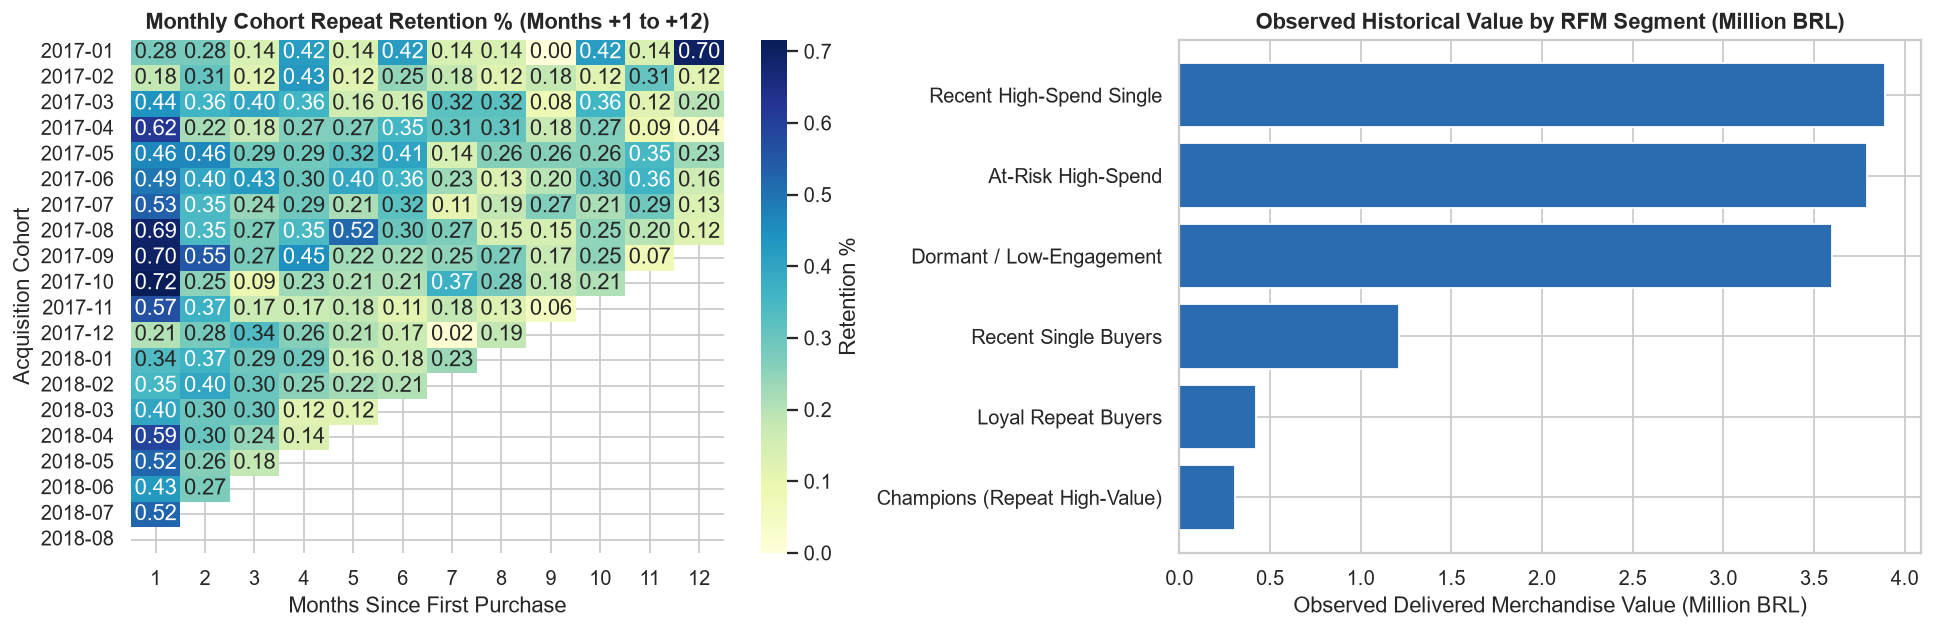

In [3]:
cust_cohort = deliv.groupby("customer_unique_id", as_index=False)["purchase_date"].min().rename(columns={"purchase_date": "first_date"})
cust_cohort["cohort_ym"] = cust_cohort["first_date"].dt.to_period("M")

deliv_c = deliv.merge(cust_cohort, on="customer_unique_id", how="inner")
deliv_c["order_ym"] = deliv_c["purchase_date"].dt.to_period("M")
deliv_c["cohort_index"] = (deliv_c["order_ym"] - deliv_c["cohort_ym"]).apply(lambda p: p.n)

core_c = deliv_c[(deliv_c["cohort_ym"] >= "2017-01") & (deliv_c["cohort_ym"] <= "2018-08")].copy()
cohort_counts = core_c.groupby(["cohort_ym", "cohort_index"])["customer_unique_id"].nunique().unstack(fill_value=0)
max_period = pd.Period("2018-08", freq="M")
for idx_c in cohort_counts.index:
    max_obs_offset = (max_period - idx_c).n
    for col_offset in cohort_counts.columns:
        if col_offset > max_obs_offset:
            cohort_counts.loc[idx_c, col_offset] = np.nan

cohort_sizes = cohort_counts[0]
retention_pct = cohort_counts.divide(cohort_sizes, axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ret_m1_12 = retention_pct.loc[:, 1:12]
sns.heatmap(ret_m1_12, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "Retention %"})
axes[0].set_title("Monthly Cohort Repeat Retention % (Months +1 to +12)", fontweight="bold")
axes[0].set_ylabel("Acquisition Cohort")
axes[0].set_xlabel("Months Since First Purchase")

axes[1].barh(seg_summary["rfm_segment"][::-1], seg_summary["total_monetary_brl"][::-1] / 1e6, color="#2b6cb0")
axes[1].set_title("Observed Historical Value by RFM Segment (Million BRL)", fontweight="bold")
axes[1].set_xlabel("Observed Delivered Merchandise Value (Million BRL)")

plt.tight_layout()
fig.savefig(FIG_DIR / "cust_01_cohort_retention_and_rfm.png", dpi=150)
plt.show()

## 3. Observed Customer Value vs. Illustrative Future Value Model
- **Observed Historical Value:** Mean **BRL 141.62** per unique customer (**BRL 13,221,498.11** total across 93,358 customers).
- **Illustrative Sensitivity CLV (Not Observed Profit):** Because repeat purchase rate is only **3.00%** over ~20 months, parametric BG/NBD forward projections have high structural uncertainty; we export clean customer-level RFM records and compute an **illustrative** 12-month gross-margin sensitivity benchmark (`observed_spend * illustrative_margin_15pct`, clearly separated from observed BRL).

In [4]:
rfm["illustrative_15pct_gross_margin_brl"] = (rfm["monetary_brl"] * 0.15).round(2)
rfm_export_cols = [
    "customer_unique_id", "primary_state", "recency_days", "frequency",
    "monetary_brl", "r_score", "f_score", "m_score", "rfm_segment", "cluster_id",
    "is_repeat", "illustrative_15pct_gross_margin_brl"
]
rfm[rfm_export_cols].to_csv(PROJECT_ROOT / "data" / "processed" / "customer_rfm_segments.csv", index=False)

lines = [
    "# CommerceIQ — Customer Intelligence Report (Phase 11)",
    "",
    f"**Analysis Reference Date:** `2018-09-01` | **Persistent ID:** `customer_unique_id`",
    f"- **Unique Delivered Customers:** {len(rfm):,}",
    f"- **Repeat Customers (>= 2 delivered orders):** {int(rfm['is_repeat'].sum()):,} (**{rfm['is_repeat'].mean()*100:.2f}%**)",
    f"- **Observed Mean / Median Historical Spend:** BRL {rfm['monetary_brl'].mean():,.2f} / BRL {rfm['monetary_brl'].median():,.2f}",
    f"- **K-Means Clustering Quality:** Best k={best_k} achieved Silhouette Score = **{sil_df.loc[sil_df['k']==best_k,'silhouette'].iloc[0]:.4f}** (separating repeat buyers, recent single buyers, high-value single buyers, and dormant cohorts).",
    "",
    "## RFM Segment Breakdown",
    "",
    "| Segment | Customers | Share % | Avg Recency (d) | Avg Freq | Avg Spend (BRL) | Total Value (BRL) |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for r in seg_summary.itertuples(index=False):
    lines.append(f"| {r.rfm_segment} | {r.customers:,} | {r.customer_pct:.2f}% | {r.avg_recency_days:.1f} | {r.avg_frequency:.3f} | {r.avg_monetary_brl:,.2f} | {r.total_monetary_brl:,.2f} |")
lines.extend([
    "",
    "## Targeted Retention Recommendations",
    "1. **Recent Single Buyers & Recent High-Spend Single (~39% of customers):** Trigger post-delivery 14–30 day cross-category replenishment offers (`bed_bath_table`, `health_beauty`, `housewares`) before the critical first-90-day drop-off.",
    "2. **Champions & Loyal Repeat Buyers (3.0% of customers):** Protect SLA reliability (prioritize fast carrier lanes) and offer loyalty bundles; repeat buyers spend nearly 2x single-order buyers.",
    "3. **At-Risk High-Spend:** Run targeted win-back campaigns paired with delivery guarantee messaging.",
    "",
])
(PROJECT_ROOT / "reports" / "customer_intelligence_report.md").write_text("\n".join(lines), encoding="utf-8")
print("Saved data/processed/customer_rfm_segments.csv and reports/customer_intelligence_report.md")

Saved data/processed/customer_rfm_segments.csv and reports/customer_intelligence_report.md
